# LightGBM: resultados y diagnóstico de validación (Fase 3)

Este notebook consulta las dos búsquedas archivadas y su diagnóstico offline.
No carga el dataset ni estimadores y no ejecuta entrenamiento, predicción u Optuna.
La convención de residuos y las cinco figuras siguen el cierre de XGBoost.

## 1. Alcance, métricas y configuración

Se comparan las mismas filas de validación, las dos búsquedas y los baselines.
Los parámetros completos y rangos provienen de los contratos guardados. Se
mantienen las quince variables oficiales. El objetivo de cada fila es el consumo
del bloque siguiente a la fecha rotulada de emisión D, no necesariamente DIA + 1 físico.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import Image, Markdown, display

raiz = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(raiz / "src"))
from diagnostico_lightgbm import auditar_tracking, huella

carpeta = raiz / "results/lightgbm_diagnostico_validacion"
verificacion = json.loads((carpeta / "verificacion.json").read_text(encoding="utf-8"))
print("Tabla 1. Métricas de validación y baselines sobre las mismas filas")
display(pd.read_csv(carpeta / "comparacion_validacion.csv").round(4))
print("Tabla 2. Parámetros completos de ambos ganadores")
display(pd.read_csv(carpeta / "hiperparametros.csv").pivot(index="hiperparametro", columns="experimento", values="valor"))
print("Tabla 3. Espacios de búsqueda originales")
display(pd.read_csv(carpeta / "espacios_busqueda.csv"))

Tabla 1. Métricas de validación y baselines sobre las mismas filas


,experimento,filas,mae,rmse,r2
0,primera,171,2321.0388,2937.7584,0.4286
1,segunda,171,2276.7354,2873.1357,0.4535
2,persistencia,171,2668.3275,3319.4336,0.2705
3,media_movil,171,2497.6536,3368.0752,0.2490


Tabla 2. Parámetros completos de ambos ganadores


experimento,primera,segunda
hiperparametro,,
colsample_bytree,0.852656,0.863854
learning_rate,0.034242,0.036985
max_depth,6.000000,3.000000
min_child_samples,30.000000,31.000000
n_estimators,181.000000,200.000000
n_jobs,1.000000,1.000000
num_leaves,19.000000,8.000000
random_state,42.000000,42.000000
reg_alpha,0.049367,0.417245


Tabla 3. Espacios de búsqueda originales


,experimento,hiperparametro,tipo,low,high,log
0,primera,n_estimators,int,100.000,500.0,NaN
1,primera,learning_rate,float,0.020,0.1,NaN
2,primera,max_depth,int,3.000,6.0,NaN
3,primera,num_leaves,int,8.000,31.0,NaN
4,primera,min_child_samples,int,20.000,60.0,NaN
5,primera,subsample,float,0.750,1.0,NaN
6,primera,colsample_bytree,float,0.750,1.0,NaN
7,primera,reg_alpha,float,0.001,10.0,True
8,primera,reg_lambda,float,0.001,10.0,True
9,segunda,n_estimators,int,150.000,900.0,NaN


## 2. Predicciones frente a valores reales

La diagonal representa predicción exacta. Cada panel conserva las observaciones
del mismo experimento. La serie temporal posterior une únicamente filas disponibles;
no se interpolan huecos ni se usan fechas repetidas como clave de identidad.

Figura 1. Predicción frente a real


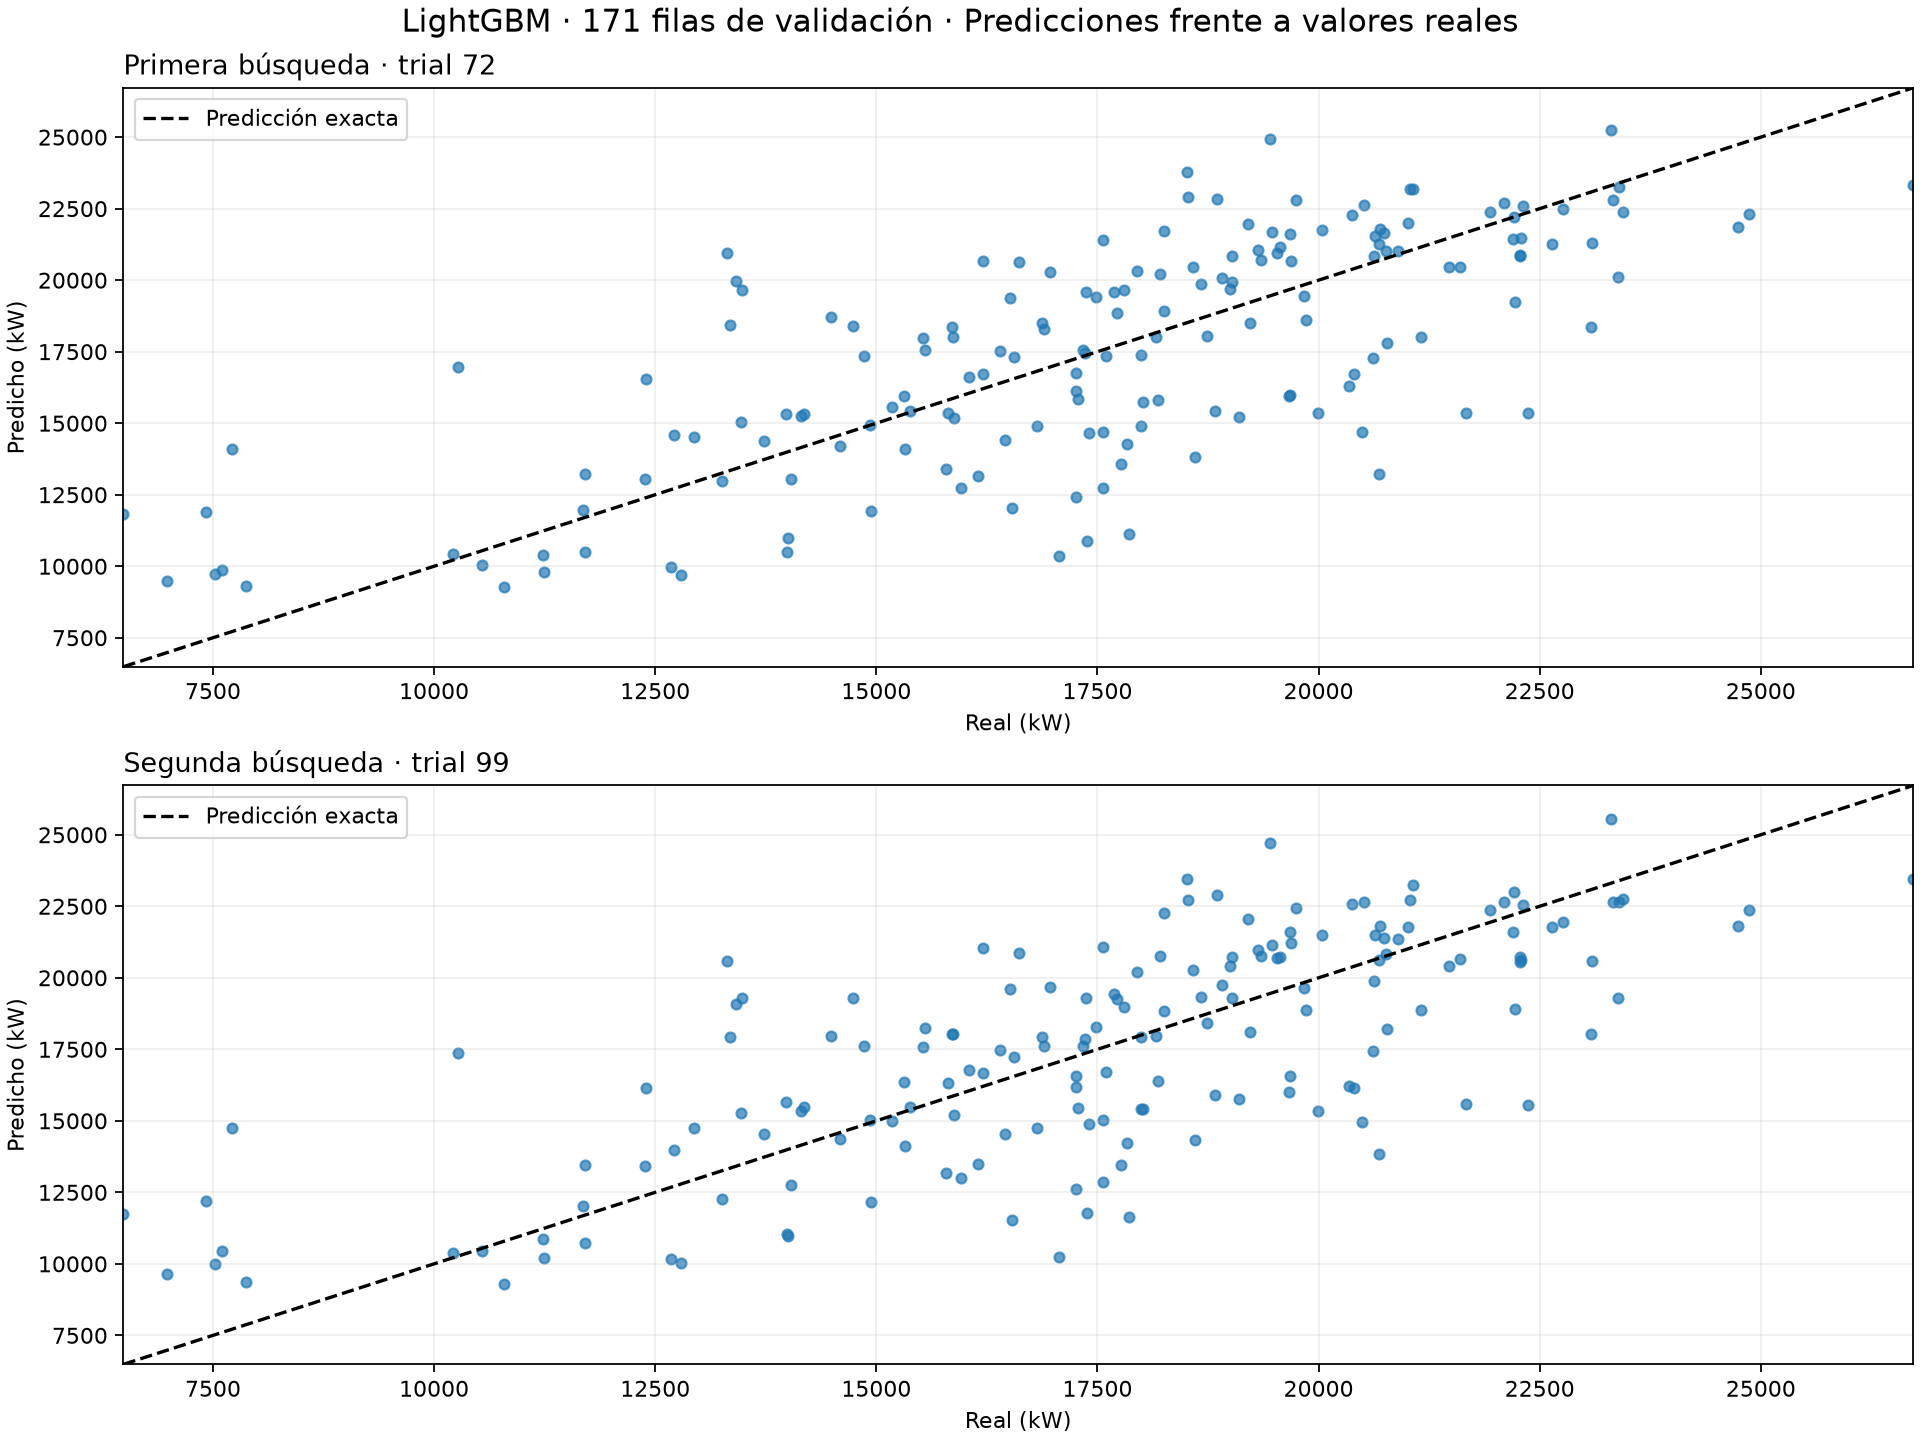

In [2]:
print("Figura 1. Predicción frente a real")
display(Image(filename=str(carpeta / "prediccion_vs_real.png")))

La serie temporal permite localizar cambios de nivel y caídas que las predicciones no anticiparon. Las fechas son las de emisión, no las del objetivo.

Figura 2. Valores reales y predichos en el tiempo


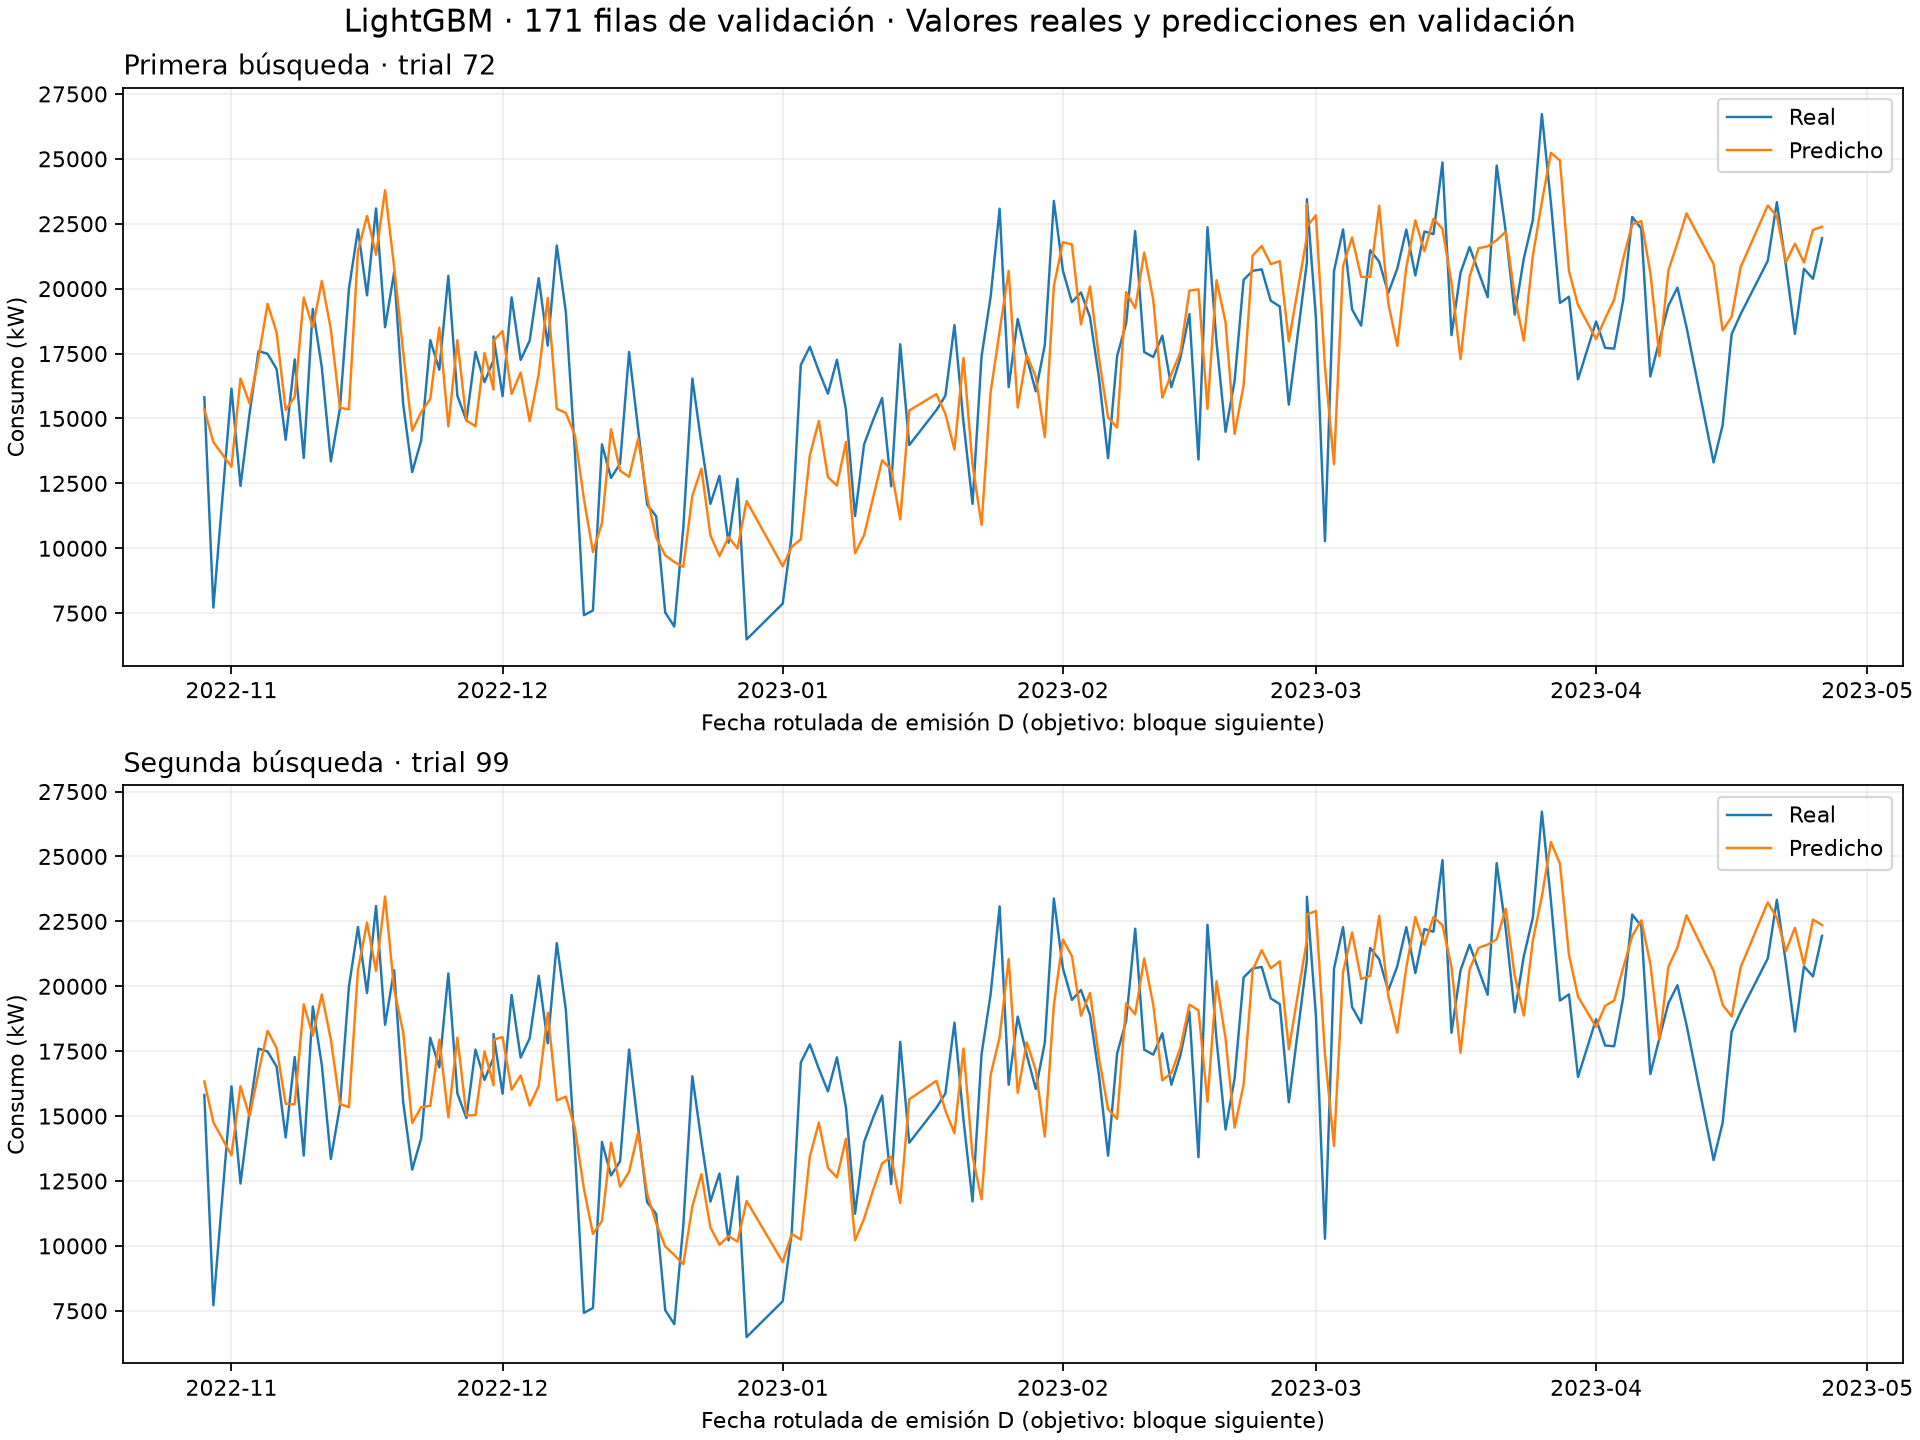

In [3]:
print("Figura 2. Valores reales y predichos en el tiempo")
display(Image(filename=str(carpeta / "predicciones_temporales.png")))

## 3. Distribución y magnitud del error

El residuo es real menos predicho: positivo indica subestimación y negativo,
sobreestimación. El histograma usa los mismos intervalos para las dos búsquedas.
La cercanía de la media a cero no demuestra precisión, normalidad ni independencia.

Figura 3. Distribución de residuos


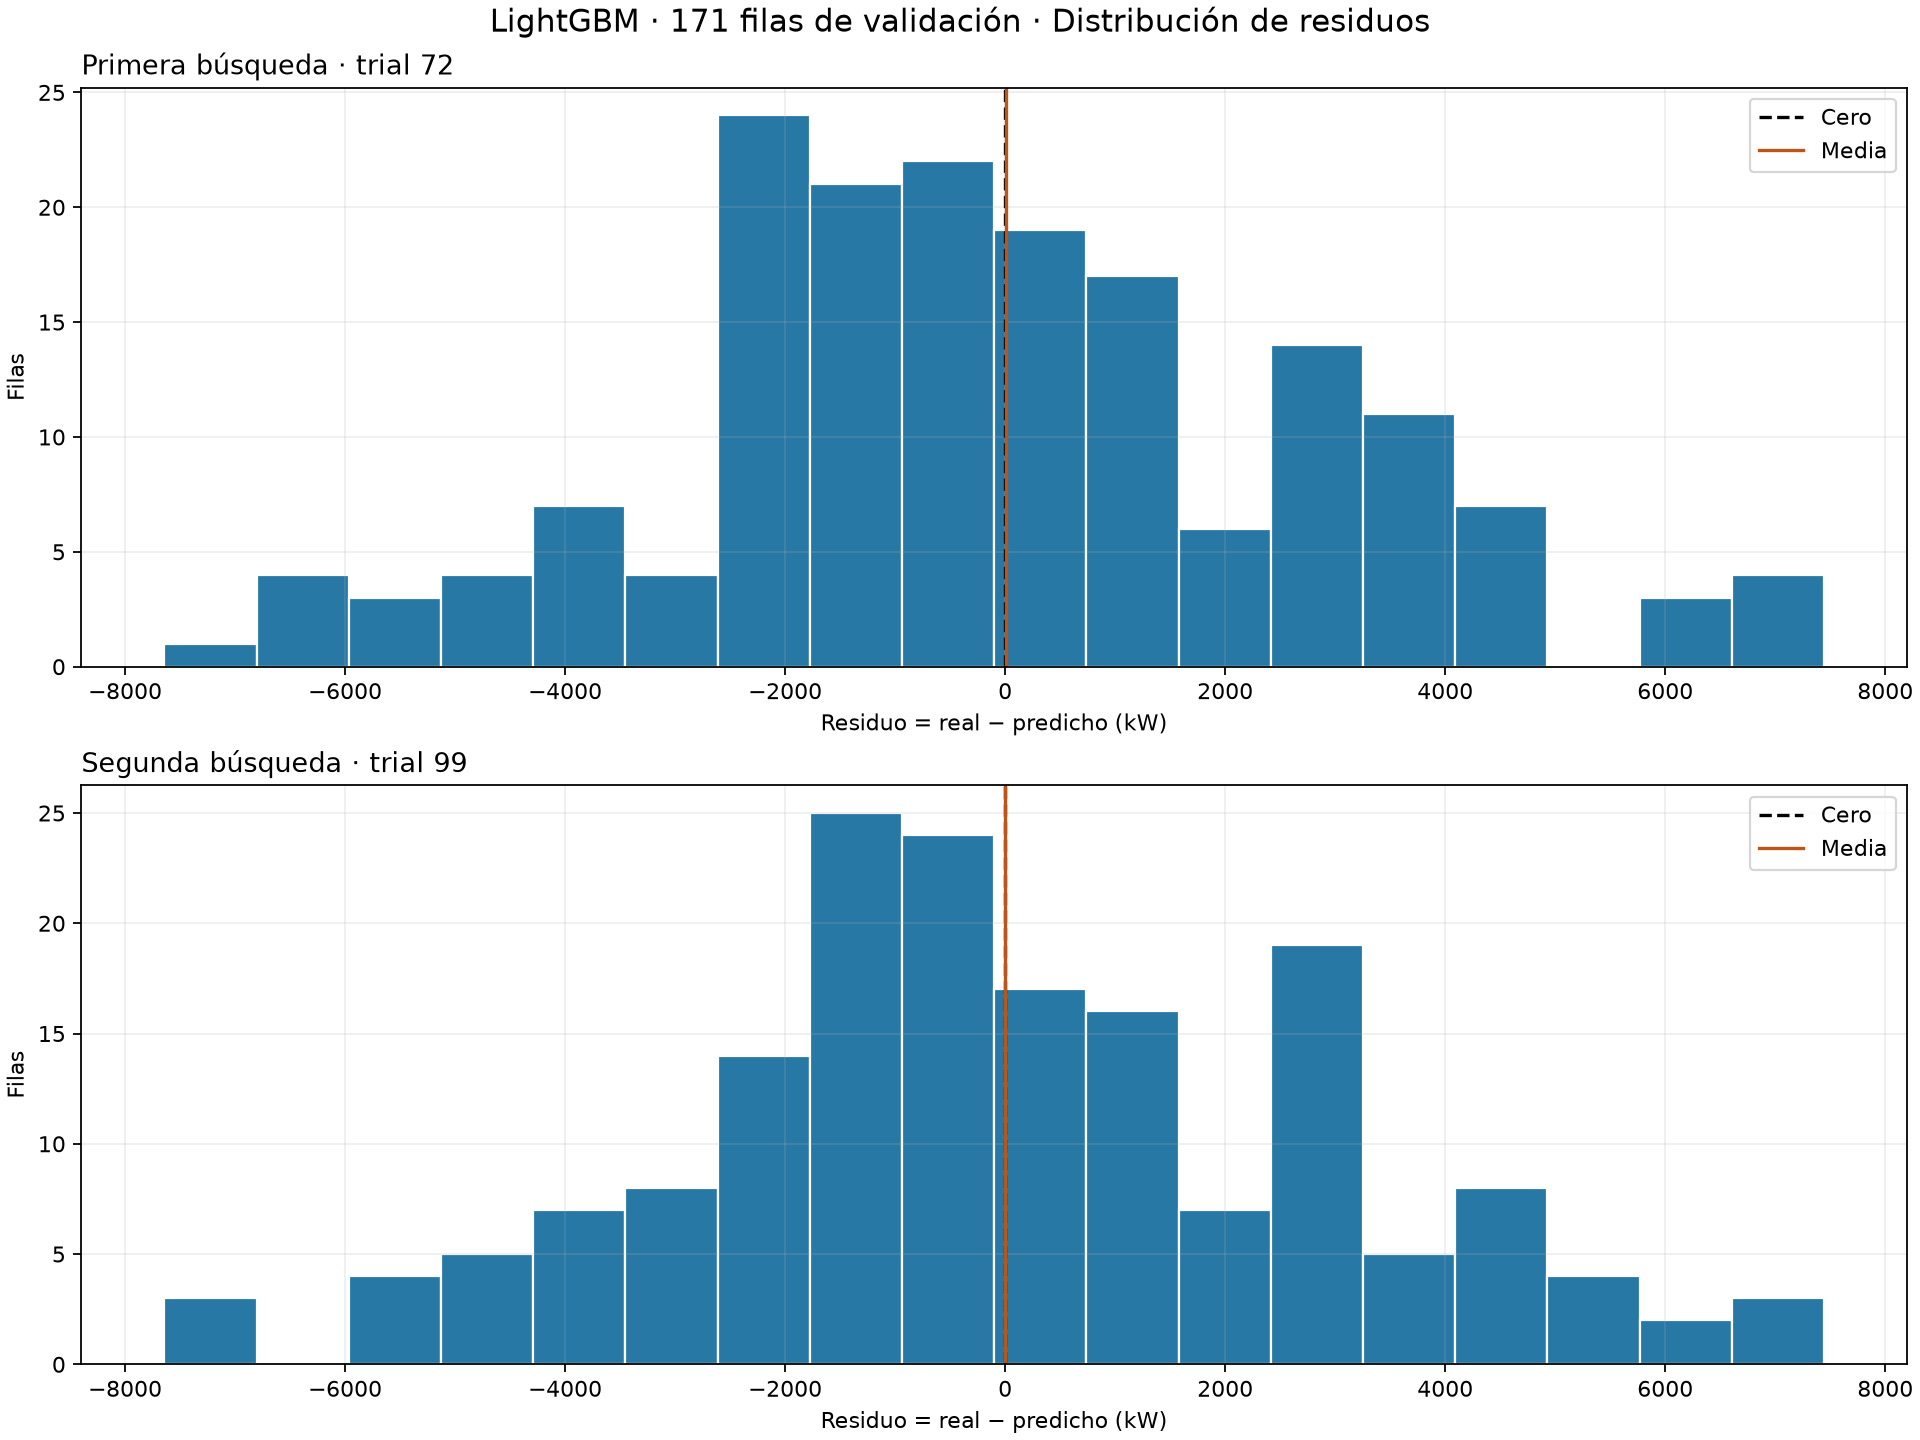

In [4]:
print("Figura 3. Distribución de residuos")
display(Image(filename=str(carpeta / "distribucion_residuos.png")))

La tabla separa sesgo, dispersión, percentiles y concentración de los errores. Todas las cifras se derivan de los CSV archivados, sin descartar casos difíciles.

In [5]:
print("Tabla 4. Resumen de residuos")
display(pd.read_csv(carpeta / "resumen_residuos.csv").round(4))

Tabla 4. Resumen de residuos


,experimento,trial,mae_cv,mae,rmse,r2,filas,sesgo_real_menos_predicho,mediana_residuo,desvio_residuo,p05_residuo,p95_residuo,p95_error_absoluto,max_error_absoluto,subestimaciones,sobreestimaciones,fraccion_error_top10
0,primera,72,3982.2353,2321.0388,2937.7584,0.4286,171,8.5023,-236.2650,2946.3738,-4780.2915,4801.1794,6334.0303,7642.3465,79,92,0.1712
1,segunda,99,3948.7261,2276.7354,2873.1357,0.4535,171,-2.5670,-293.3434,2881.5725,-4813.1235,4860.0932,5742.0295,7285.3624,79,92,0.1686


## 4. Nivel predicho, evolución temporal y errores mayores

Se examina la nube de residuos por nivel predicho y su evolución. Los patrones
visuales son descriptivos; no se atribuye causalidad ni se modifica el modelo.

Figura 4. Residuos frente a predicciones


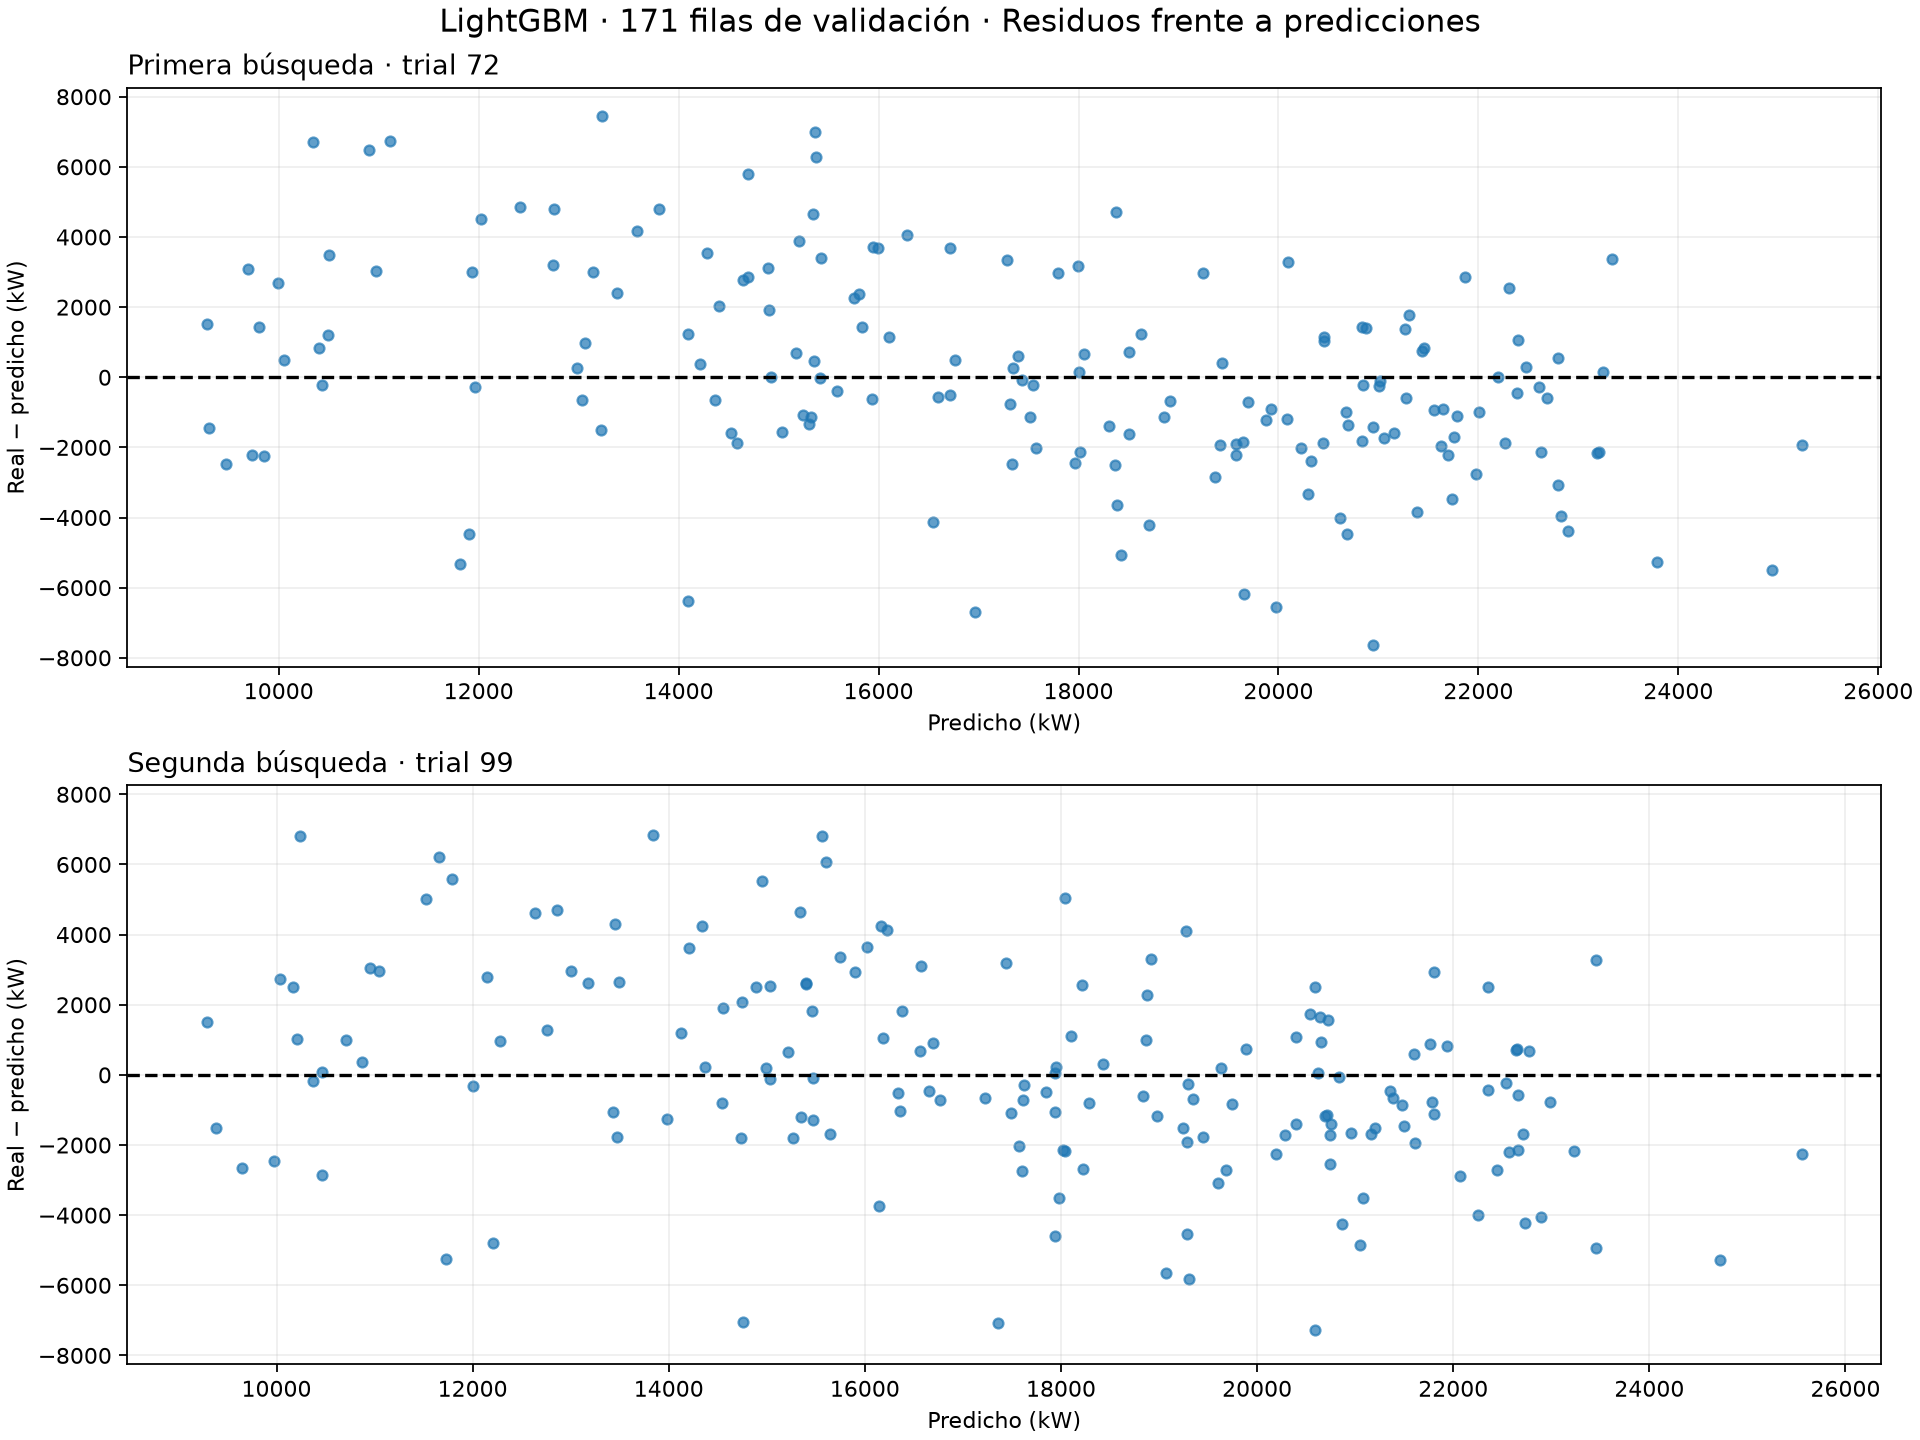

In [6]:
print("Figura 4. Residuos frente a predicciones")
display(Image(filename=str(carpeta / "residuos_vs_predicciones.png")))

La figura temporal conserva el mismo signo y escalas entre candidatos. La tabla mensual posterior incluye la cantidad de filas porque los meses parciales tienen menos evidencia.

Figura 5. Evolución temporal de residuos


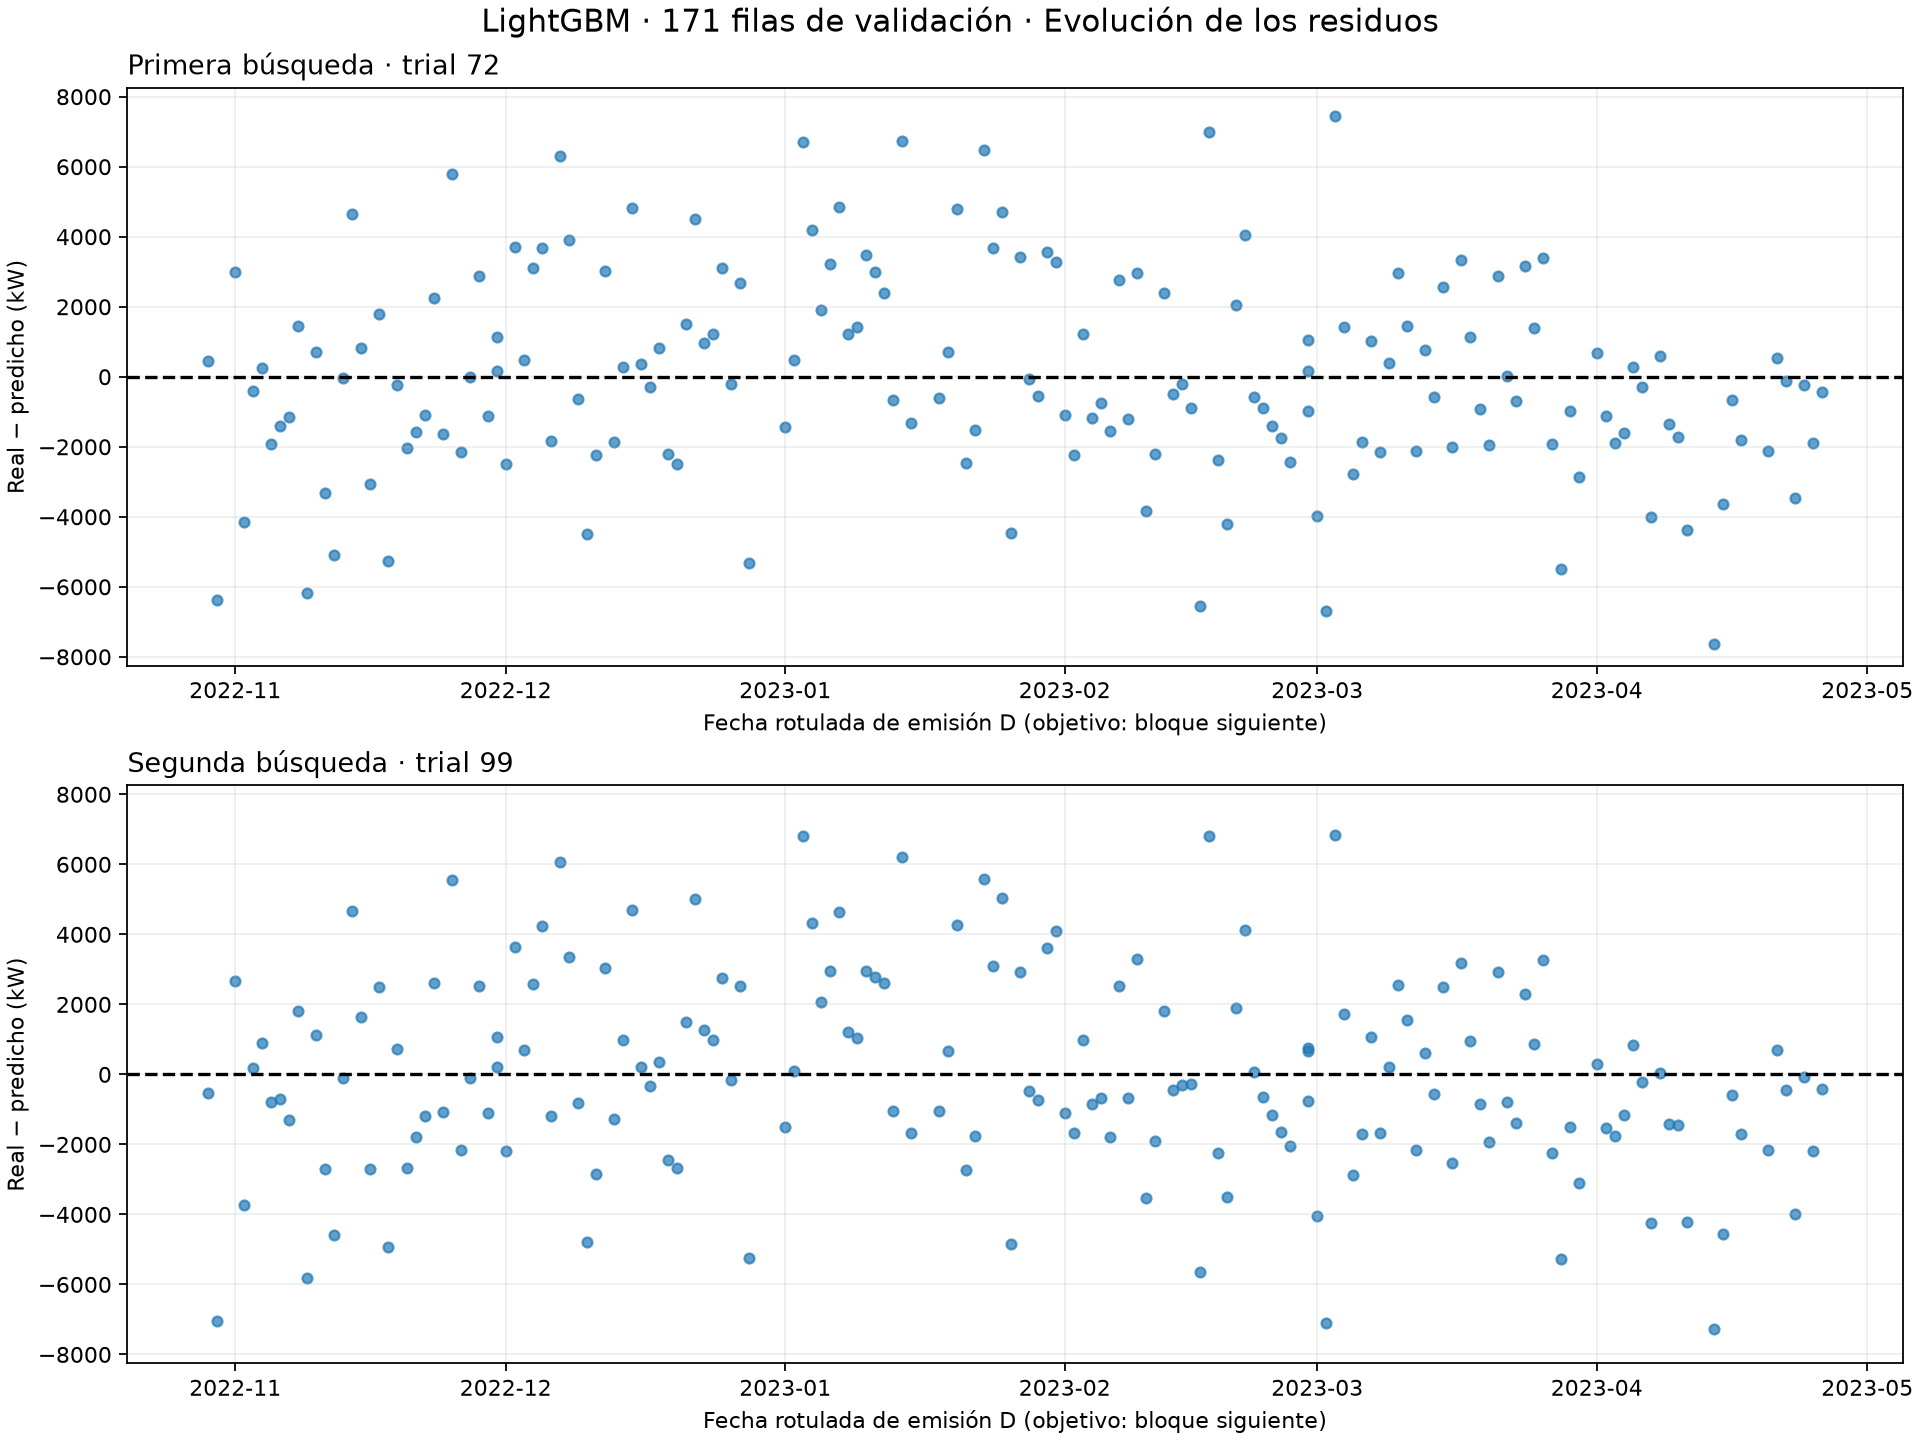

In [7]:
print("Figura 5. Evolución temporal de residuos")
display(Image(filename=str(carpeta / "residuos_temporales.png")))

Los errores mayores se identifican por indice_csv para evitar cruces ambiguos por fecha. Se conservan las diez mayores desviaciones de cada búsqueda y no se eliminan para mejorar métricas.

In [8]:
print("Tabla 5. Sesgo y MAE por mes de emisión")
display(pd.read_csv(carpeta / "residuos_por_mes.csv").round(3))
print("Tabla 6. Diez errores mayores de cada búsqueda")
display(pd.read_csv(carpeta / "errores_mayores.csv").round(3))

Tabla 5. Sesgo y MAE por mes de emisión


,experimento,mes_emision,filas,sesgo,mae
0,primera,2022-10,2,-2957.827,3416.822
1,primera,2022-11,31,-544.820,2151.711
2,primera,2022-12,28,727.516,2449.524
3,primera,2023-01,29,1970.651,2876.598
4,primera,2023-02,29,-456.315,2087.654
5,primera,2023-03,30,-123.856,2343.962
6,primera,2023-04,22,-1650.526,1840.552
7,segunda,2022-10,2,-3783.548,3783.548
8,segunda,2022-11,31,-301.550,2119.267
9,segunda,2022-12,28,714.618,2423.790


Tabla 6. Diez errores mayores de cada búsqueda


,indice_csv,DIA,real,predicho,residuo,error_absoluto,experimento
0,994,2023-04-14,13306.0,20948.347,-7642.347,7642.347,primera
1,954,2023-03-03,20679.0,13236.679,7442.321,7442.321,primera
2,938,2023-02-17,22369.0,15365.894,7003.106,7003.106,primera
3,905,2023-01-14,17859.0,11110.777,6748.223,6748.223,primera
4,894,2023-01-03,17060.0,10344.211,6715.789,6715.789,primera
5,953,2023-03-02,10274.0,16964.613,-6690.613,6690.613,primera
6,937,2023-02-16,13416.0,19971.513,-6555.513,6555.513,primera
7,913,2023-01-23,17384.0,10899.356,6484.644,6484.644,primera
8,831,2022-10-30,7714.0,14088.649,-6374.649,6374.649,primera
9,869,2022-12-07,21663.0,15369.589,6293.411,6293.411,primera


## 5. Tracking y controles de preservación

La auditoría concilia cada experimento completo y las validaciones con el log,
preservando timestamps y el estado Git real. La granularidad por experimento
deja parcialmente cubierta la exigencia literal de cada entrenamiento de 3.2.
Las fuentes inmutables y la firma de filas propias se comprueban por separado
para permitir integrar registros de otras familias sin invalidar los de LightGBM.

In [9]:
auditoria, tracking = auditar_tracking(raiz)
print("Tabla 7. Alcance y límites del tracking")
display(pd.DataFrame([{k: v for k, v in tracking.items() if k != "estudios"}]))
controles = dict(verificacion["controles"])
controles["fuentes_inmutables_intactas"] = all(
    huella(raiz / ruta) == valor for ruta, valor in verificacion["fuentes_sha256"].items()
    if ruta != "results/experiment_logs.csv")
controles["registros_lightgbm_intactos"] = tracking["registros_propios_sha256"] == verificacion["tracking"]["registros_propios_sha256"]
print("Tabla 8. Controles; todos deben ser verdaderos")
display(pd.Series(controles, name="Cumple").to_frame())
assert all(controles.values()), controles

Tabla 7. Alcance y límites del tracking


,registros_lightgbm,cv_completos,validaciones,registros_propios_sha256,cumplimiento_literal_por_ajuste,limite
0,86,84,2,cb1b69831f08685c8774c0ab3875e2161fbfe5afc5520b...,Parcial,Una fila por COMPLETE agrupa cinco ajustes. Lo...


Tabla 8. Controles; todos deben ser verdaderos


,Cumple
metricas_coinciden_con_evaluaciones,True
mismas_171_filas_y_objetivos,True
contrato_15_variables_igual,True
ganadores_y_parametros_verificados,True
tracking_conciliado,True
originales_intactos,True
fuentes_inmutables_intactas,True
registros_lightgbm_intactos,True


## 6. Conclusión

El informe documenta las diferencias entre búsquedas, los sesgos temporales, la
dispersión y los errores mayores. Explicita los pendientes del ganador global,
sin convertir los gráficos de Optuna en importancia de las variables del modelo.

In [10]:
informe = (carpeta / "informe.md").read_text(encoding="utf-8")
# Las figuras ya se mostraron arriba; el informe conserva aquí su interpretación.
display(Markdown("\n".join(linea for linea in informe.splitlines() if not linea.startswith("!["))))

# Diagnóstico archivado de LightGBM — Fase 3

Análisis del 15/11/2026, basado exclusivamente en `results/lightgbm/`,
`results/lightgbm_2/` y el log de experimentos. No se abrió el dataset, ningún modelo
serializado ni el conjunto de prueba. No se ejecutaron entrenamientos, predicciones
ni búsquedas. Las fuentes históricas se preservaron por SHA-256 en `verificacion.json`.

## 1. Datos, convención y comparación

Las dos búsquedas usaron las mismas 15 variables, nombres y orden, según sus
contratos archivados, cinco pliegues temporales con gap=1 y semilla 42. Cada ganador
se ajustó originalmente con 830 filas y se evaluó en las mismas 171 filas comunes
de validación. En este cierre solo se leyeron las predicciones ya guardadas.

El residuo se define como real menos predicho: positivo indica subestimación y
negativo, sobreestimación. La identidad se comprueba por indice_csv, no por DIA,
porque hay fechas repetidas. DIA es la fecha rotulada de emisión D; el objetivo es
el bloque siguiente, que no necesariamente coincide con el día físico D+1. Las
líneas temporales unen solo observaciones disponibles; no se imputan días omitidos.

| Búsqueda / referencia | MAE CV | MAE validación | RMSE validación | R² validación |
|---|---:|---:|---:|---:|
| Primera, trial 72 | 3982,24 | 2321,04 | 2937,76 | 0,4286 |
| Segunda, trial 99 | 3948,73 | 2276,74 | 2873,14 | 0,4535 |
| Persistencia | — | 2668,33 | 3319,43 | 0,2705 |
| Media móvil | — | 2497,65 | 3368,08 | 0,2490 |

La segunda búsqueda reduce MAE CV en 33,51 kW (0,84 %) y MAE de validación en
44,30 kW (1,91 %) frente a la primera. Es una mejora descriptiva pequeña; no se
afirma significación estadística. Frente a la media móvil, el segundo candidato
mejora aproximadamente 8,85 % en validación, menos del 10 %. Esto no acredita la
mejora ni el MAE exigidos en el test oculto. No se elige al ganador global aquí.

`comparacion_validacion.csv` conserva las métricas de candidatos y baselines;
`hiperparametros.csv` incluye parámetros fijos y optimizados completos, y
`espacios_busqueda.csv` conserva los rangos efectivos de los contratos originales.

## 2. Predicciones y residuos


La diagonal representa predicción exacta. Ambos candidatos acompañan el nivel
del consumo, con dispersión visible y dificultad para anticipar algunas caídas
bruscas. No se recalibró ni se ajustó una recta sobre las predicciones.


Las series conservan los cambios de nivel y los desaciertos de ambas búsquedas.
La similitud visual no significa que sus errores sean iguales: las métricas se
verificaron por separado contra los JSON de validación y sus registros del log.


| Resumen | Primera | Segunda |
|---|---:|---:|
| Sesgo promedio (kW) | +8,50 | −2,57 |
| Mediana del residuo (kW) | −236,27 | −293,34 |
| Desvío del residuo (kW, muestral) | 2946,37 | 2881,57 |
| Percentil 95 del error absoluto (kW) | 6334,03 | 5742,03 |
| Mayor error absoluto (kW) | 7642,35 | 7285,36 |
| Subestimaciones / sobreestimaciones | 79 / 92 | 79 / 92 |
| Fracción del error absoluto en las diez peores filas | 17,12 % | 16,86 % |

El promedio casi nulo no representa precisión perfecta: conviven sobreestimaciones
y subestimaciones grandes. La segunda búsqueda reduce dispersión y cola del error
absoluto, aunque mantiene errores superiores a 7000 kW y el mismo conteo por signo.
El histograma no demuestra normalidad ni independencia. Los percentiles son
descriptivos de estas 171 observaciones, no intervalos de predicción futuros.


Se aprecia predominio de residuos negativos en la zona de predicciones altas y
errores positivos importantes en niveles intermedios o bajos. La nube no parece
completamente homogénea. Es una lectura visual, sin prueba formal de
heterocedasticidad ni atribución causal al funcionamiento de la planta.


El sesgo global cancela diferencias temporales: en enero de 2023, sobre 29 filas,
la primera búsqueda subestima 1970,65 kW en promedio y la segunda 1763,20 kW. En
abril, sobre 22 filas, sobreestiman 1650,53 y 1706,69 kW respectivamente. La segunda
no mejora uniformemente en cada período. Octubre tiene solo dos filas y no es una
comparación mensual estable. `residuos_por_mes.csv` conserva los tamaños y valores.

## 3. Errores mayores

El máximo error de la primera búsqueda es una sobreestimación de 7642,35 kW en
indice_csv 994, emisión 14/04/2023: real 13306,00 y predicho 20948,35 kW. La fila
siguiente del ranking, índice 954 y emisión 03/03/2023, es una subestimación de
7442,32 kW: real 20679,00 y predicho 13236,68 kW. Hay errores grandes de ambos signos.

`errores_mayores.csv` conserva las diez mayores desviaciones de cada búsqueda,
incluyendo índices, fechas, valores reales, predichos y residuos. No se eliminan
filas según su error ni se atribuyen a fallas operativas que estas predicciones
no permiten comprobar. Los residuos completos se guardan en dos CSV propios.

## 4. Optimización y tracking

Ambos estudios tienen 100 trials: 38 COMPLETE y 62 PRUNED en el primero; 46 COMPLETE
y 54 PRUNED en el segundo, sin fallidos. Se conserva TPESampler(seed=42),
MedianPruner y el MAE conjunto de las 677 filas comunes de los cinco pliegues, en
vez de promediar sin ponderación los MAE de pliegues de distinto tamaño.

La segunda búsqueda amplió árboles a 150–900, tasa a 0,01–0,10, mínimo por hoja a
10–60 y fracción de columnas a 0,65–1,00. Mantuvo profundidad 3–6 y el límite
condicionado num_leaves <= min(31, 2**max_depth). El segundo ganador tiene 200
árboles, profundidad 3, ocho hojas y tasa 0,036985470389312915. No hay imputación,
escalado, transformación del objetivo ni early stopping adicionales. Ver ADR 0021/0022.

`auditoria_tracking.csv` concilia los 84 COMPLETE y las dos validaciones con las
86 filas LightGBM de `results/experiment_logs.csv`. Verifica hiperparámetros
completos, MAE/RMSE/R², filas, semilla, commits y timestamps originales. Las métricas
de los CSV de validación coinciden con las históricas con rtol=1e-10 y atol=1e-8,
sin convertir las predicciones LightGBM a float32 ni modificar resultados.

El cumplimiento literal de 3.2 sigue siendo parcial: el CSV contiene un registro
por experimento COMPLETE que agrupa cinco ajustes; los podados están en los estudios
y sus JSON. Los timestamps son de registro, no del comienzo de cada ajuste, y no
tienen zona horaria. Las corridas tienen arbol_sin_commitear=True: se preserva ese
hecho, respaldado por snapshots de código y hashes. No se fabrican registros,
fechas ni métricas finales para completar retrospectivamente el tracking.

## 5. Reproducción y límites

Con Python 3.12 y las dependencias existentes, desde la raíz del repositorio:

```powershell
python -B src/diagnostico_lightgbm.py
python -B src/actualizar_notebook_lightgbm.py
python -B -m pytest tests/test_diagnostico_lightgbm.py -q -p no:cacheprovider
```

El primer comando genera solo las tablas, figuras y verificación del diagnóstico;
este informe interpretativo se conserva como documentación. El segundo genera y
ejecuta únicamente el notebook LightGBM de consulta, que no contiene estimadores.
Requiere el kernel cervecera_env. El tercero no ejecuta entrenamiento ni Optuna.
No ejecutar las suites de modelado ni `comparar_lightgbm.py`: contienen operaciones
con estimadores que quedan fuera del alcance autorizado de este cierre.

Se reutilizan las funciones puras de `src/diagnostico_xgboost.py`, ya integrado
en la base, sin modificarlo. Las fuentes originales se verifican por SHA-256.
La firma semántica de las filas LightGBM permite verificar su preservación aunque
el log común reciba registros de otras familias. No se agregaron dependencias.

Con estos gráficos y conclusiones queda cubierto el diagnóstico descriptivo de
3.3 para ambos candidatos LightGBM. La importancia de variables corresponde al
mejor modelo global; la f-ANOVA existente es importancia de hiperparámetros. No
se extraen importancias de los modelos guardados ni se inventan valores aquí.
Quedan para integración el notebook común, comparación de familias, selección,
reentrenamiento final, registry, versión semántica y etiqueta Git. Los modelos
guardados actualmente son de validación, no sustituyen esos entregables.

La selección de variables no está anidada y validación ya intervino en decisiones
anteriores. Este análisis añade inspección del mismo período, sin transformarlo
en una evaluación independiente ni justificar otro ajuste. Los cambios mensuales
no prueban causa operativa o generalización. El test permanece reservado.